# Categorical encoding

Compare the current one-hot baseline with frequency and smoothed temporal target encoding, replacing one categorical feature at a time. All variants share median imputation, Unknown, the configured rare-category grouping, and the same predictors with imputation indicators excluded.

Four validation folds (2020–2023) use three-year training windows and a 90-day label embargo. Models are fixed: logistic regression and random forest for repeat purchase, Ridge and random forest for conditional spending. The 2024 holdout is reserved.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score, mean_absolute_error

project = Path.cwd()
if not (project / "config.yaml").is_file():
    project = project.parent
if not (project / "config.yaml").is_file():
    raise FileNotFoundError("Start the notebook from the project root or notebooks directory.")
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from src.data_loader import load_config
from src.feature_transformer import (
    IMPUTATION_INDICATOR_SUFFIXES,
    RareCategoryEncoder,
    apply_feature_transformer,
    fit_feature_transformer,
)
from src.imputation import ImputationPreprocessor, estimators, regression_mask
from src.preprocessing import prepare_rows
from src.validation import temporal_cv

config = load_config()
preprocessing = config["preprocessing"]
preprocessing["numeric_imputation"]["strategy"] = "median"
preprocessing["categorical_missing"]["strategy"] = "unknown"
preprocessing["feature_selection"]["include_imputation_indicators"] = False
validation = config["validation"]
date_col = preprocessing["date_features"]["source_column"]
repeat_col = config["columns"]["classification_target"]
spend_col = config["columns"]["regression_target"]
horizon = pd.Timedelta(days=validation["target_horizon_days"])
features = ["transport_method", "payment_type", "salesperson", "commercial_zone"]
variants = [("one-hot", None)] + [
    (method, feature) for feature in features for method in ("frequency", "target")
]
raw = pd.read_csv(project / config["paths"]["train"])
year = pd.to_datetime(raw[date_col], errors="coerce").dt.year
development = prepare_rows(raw.loc[year.le(max(validation["cv_years"]))], config)

## Encoding rules

Frequency is the proportion of the grouped level in the fold's training rows. Unseen levels use the learned Other bucket when available and otherwise receive zero.

Target encoding uses 20 observations' worth of shrinkage toward the eligible global mean. A training row can only use labels available strictly before its purchase date. The earliest rows without any eligible label are omitted from model training for every variant of the corresponding task. They can still supply labels to later rows. Validation uses frozen training statistics. The spending encoder uses only returners with observed spending.

In [2]:
def grouped_levels(prepared, encoder):
    grouping = encoder.named_transformers_["rare_categorical"]
    return grouping.group_categories(prepared[features].astype(str))


def frequency_values(training_levels, query_levels):
    frequencies = training_levels.value_counts(normalize=True)
    return query_levels.map(frequencies).fillna(0.0)


def totals_before(donors, query_dates):
    ordered = donors.sort_values("available", kind="stable")
    count = np.searchsorted(
        ordered["available"].to_numpy(dtype="datetime64[ns]"),
        query_dates.to_numpy(dtype="datetime64[ns]"),
        side="left",
    )
    cumulative = np.r_[0.0, ordered["target"].to_numpy(dtype=float).cumsum()]
    return count, cumulative[count]


def temporal_target_values(donors, train_levels, train_dates, validation_levels, strength=20):
    count, total = totals_before(donors, train_dates)
    prior = np.divide(total, count, out=np.full(len(total), np.nan), where=count > 0)
    training_values = pd.Series(prior, index=train_levels.index, dtype=float)
    for level, observations in donors.groupby("level", sort=False):
        is_level = train_levels.eq(level)
        level_count, level_total = totals_before(observations, train_dates.loc[is_level])
        training_values.loc[is_level] = (
            level_total + strength * prior[is_level.to_numpy()]
        ) / (level_count + strength)

    overall = donors["target"].mean()
    stats = donors.groupby("level", sort=False)["target"].agg(["sum", "count"])
    frozen = (stats["sum"] + strength * overall) / (stats["count"] + strength)
    return training_values, validation_levels.map(frozen).fillna(overall)


def replace_one_hot(matrix, feature, values):
    block = matrix.columns.str.startswith(f"rare_categorical__{feature}_")
    if not block.any():
        raise ValueError(f"No grouped one-hot block for {feature}")
    return matrix.loc[:, ~block].assign(**{f"encoded__{feature}": values})

In [3]:
# Check grouping, label availability at the exact boundary, shrinkage, and fallbacks.
group_input = pd.DataFrame({
    "with_other": ["A", "A", "Rare", "Unknown"],
    "without_other": ["A", "A", "B", "B"],
})
grouper = RareCategoryEncoder({"with_other": 2, "without_other": 2}, "Unknown").fit(group_input)
group_query = pd.DataFrame({
    "with_other": ["Unseen", "Rare", "Unknown"],
    "without_other": ["Unseen", "B", "A"],
})
grouped_train = grouper.group_categories(group_input)
grouped_query = grouper.group_categories(group_query)
assert grouped_query["with_other"].tolist() == ["Other", "Other", "Unknown"]
assert grouped_query["without_other"].tolist() == ["Unseen", "B", "A"]
np.testing.assert_allclose(frequency_values(grouped_train["with_other"], grouped_query["with_other"]), 0.25)
np.testing.assert_allclose(frequency_values(grouped_train["without_other"], grouped_query["without_other"]), [0, 0.5, 0.5])

boundary = pd.Timestamp("2020-01-01") + horizon
donor_example = pd.DataFrame({
    "available": [boundary - pd.Timedelta(days=5), boundary, boundary + pd.Timedelta(days=1)],
    "level": ["A", "B", "A"],
    "target": [10., 30., 1000.],
})
query_dates = pd.Series([boundary - pd.Timedelta(days=5), boundary, boundary + pd.Timedelta(days=1)])
query_levels = pd.Series(["A", "A", "A"])
future_levels = pd.Series(["Unseen", "B"])
historical, frozen = temporal_target_values(donor_example, query_levels, query_dates, future_levels)
np.testing.assert_allclose(historical, [np.nan, 10., (10 + 20 * 20) / 21], equal_nan=True)
overall = donor_example["target"].mean()
np.testing.assert_allclose(frozen, [overall, (30 + 20 * overall) / 21])
changed_future = donor_example.copy()
changed_future.loc[2, "target"] = 1e8
changed_historical, _ = temporal_target_values(changed_future, query_levels, query_dates, future_levels)
pd.testing.assert_series_equal(historical, changed_historical)
print("Grouping and temporal target encoding checks passed.")

Grouping and temporal target encoding checks passed.


## Temporal validation

Each comparison replaces one grouped one-hot block with a single column. All variants for a fold and task use the same rows, estimators and remaining features.

In [4]:
def evaluate_fold(fold, train, val):
    imputer = ImputationPreprocessor(config).fit(train)
    train_ready, val_ready = imputer.transform(train), imputer.transform(val)
    encoder, columns = fit_feature_transformer(train_ready, config)
    base_train = apply_feature_transformer(train_ready, encoder, columns, config)
    base_val = apply_feature_transformer(val_ready, encoder, columns, config)
    assert len(columns) == len(set(columns))
    assert not any(name.endswith(IMPUTATION_INDICATOR_SUFFIXES) for name in columns)
    assert base_train.columns.equals(base_val.columns)
    assert 80 <= base_train.shape[1] <= 90

    train_levels = grouped_levels(train_ready, encoder)
    val_levels = grouped_levels(val_ready, encoder)
    # Changing validation labels does not affect imputation, grouping, or model inputs.
    modified = val.copy()
    modified[repeat_col] = 1 - modified[repeat_col]
    modified[spend_col] = 1e8
    modified_ready = imputer.transform(modified)
    modified_levels = grouped_levels(modified_ready, encoder)
    pd.testing.assert_frame_equal(val_levels, modified_levels)
    pd.testing.assert_frame_equal(
        base_val, apply_feature_transformer(modified_ready, encoder, columns, config)
    )

    for task, label in (("classification", repeat_col), ("regression", spend_col)):
        if task == "classification":
            eligible = train[label].isin([0, 1])
            evaluation = val[label].isin([0, 1])
        else:
            eligible = regression_mask(train, config)
            evaluation = regression_mask(val, config)

        available = train.loc[eligible, date_col] + horizon
        use_train = eligible & train[date_col].gt(available.min())
        assert use_train.any() and evaluation.any()
        truth = val.loc[evaluation, label]
        for method, feature in variants:
            X_train, X_val = base_train, base_val
            if method == "frequency":
                fit_levels = train_levels[feature]
                train_values = frequency_values(fit_levels, fit_levels)
                val_values = frequency_values(fit_levels, val_levels[feature])
            elif method == "target":
                donors = pd.DataFrame({
                    "level": train_levels.loc[eligible, feature],
                    "target": train.loc[eligible, label],
                    "available": available,
                })
                train_values, val_values = temporal_target_values(
                    donors, train_levels[feature], train[date_col], val_levels[feature]
                )
                assert train_values.loc[use_train].notna().all() and val_values.notna().all()
                _, val_after_label_change = temporal_target_values(
                    donors, train_levels[feature], train[date_col], modified_levels[feature]
                )
                pd.testing.assert_series_equal(val_values, val_after_label_change)

            if feature is not None:
                X_train = replace_one_hot(base_train, feature, train_values)
                X_val = replace_one_hot(base_val, feature, val_values)
            assert X_train.columns.equals(X_val.columns)

            for name, model in estimators(config)[task].items():
                model.fit(X_train.loc[use_train], train.loc[use_train, label])
                if task == "classification":
                    positive = list(model.classes_).index(1)
                    prediction = model.predict_proba(X_val.loc[evaluation])[:, positive] >= 0.5
                    score = f1_score(truth, prediction)
                else:
                    prediction = np.maximum(0, model.predict(X_val.loc[evaluation]))
                    score = mean_absolute_error(truth, prediction)
                yield {
                    "variant": "One-hot baseline" if feature is None else f"{feature} | {method}",
                    "method": method, "task": task, "fold": fold, "model": name,
                    "score": score, "columns": X_train.shape[1], "training_rows": int(use_train.sum()),
                }


folds = temporal_cv(
    development, validation["cv_years"], validation["target_horizon_days"],
    strategy=validation["strategy"], train_years=validation["sliding_window"]["train_years"],
)
scores = pd.DataFrame(
    record for fold, train, val in folds for record in evaluate_fold(fold, train, val)
)
assert len(scores) == 144
assert scores.groupby(["variant", "task"]).size().eq(8).all()
assert scores.groupby(["fold", "task"])["training_rows"].nunique().eq(1).all()
print("144 model evaluations with matched training rows.")

144 model evaluations with matched training rows.


## Results

Scores are averaged equally across folds and models. For each task, prefer the narrowest variant within 0.005 F1 or 1% MAE of the best score. Ties in width prefer one-hot, then frequency, then target encoding, followed by the better score.

task,Mean columns,Mean F1,Mean MAE (EUR)
variant,,,
One-hot baseline,84.0,0.7093,1439.05
transport_method | frequency,65.0,0.7070,1412.99
transport_method | target,65.0,0.7065,1405.81
payment_type | frequency,79.5,0.7150,1442.40
payment_type | target,79.5,0.7143,1437.72
salesperson | frequency,80.8,0.7135,1438.28
salesperson | target,80.8,0.7133,1446.78
commercial_zone | frequency,82.8,0.7148,1437.02
commercial_zone | target,82.8,0.7159,1438.11


F1 MAE (EUR)      F1 MAE (EUR)      F1  \
fold                            2020      2020    2021      2021    2022   
variant                                                                    
One-hot baseline              0.6875   1463.35  0.7302   1403.79  0.7021   
transport_method | frequency  0.6889   1450.37  0.7199   1389.88  0.7012   
transport_method | target     0.6897   1441.55  0.7321   1377.70  0.6960   
payment_type | frequency      0.6984   1503.27  0.7415   1409.14  0.6967   
payment_type | target         0.7024   1494.51  0.7314   1412.97  0.7102   
salesperson | frequency       0.6941   1462.10  0.7291   1406.04  0.7025   
salesperson | target          0.6904   1455.44  0.7275   1411.27  0.7067   
commercial_zone | frequency   0.6973   1462.94  0.7347   1403.79  0.7048   
commercial_zone | target      0.6982   1482.54  0.7343   1433.70  0.7099   

                             MAE (EUR)      F1 MAE (EUR) Columns            \
fold                              2022    2023      2023    2020 2021 2022   
variant                                                                      
One-hot baseline               1403.54  0.7172   1485.54      81   80   86   
transport_method | frequency   1347.37  0.7180   1464.34      65   63   65   
transport_method | target      1333.92  0.7079   1470.05      65   63   65   
payment_type | frequency       1382.45  0.7234   1474.72      77   76   81   
payment_type | target          1359.43  0.7133   1483.96      77   76   81   
salesperson | frequency        1393.47  0.7283   1491.52      77   77   83   
salesperson | target           1418.21  0.7285   1502.19      77   77   83   
commercial_zone | frequency    1398.74  0.7223   1482.59      80   79   85   
commercial_zone | target       1341.02  0.7213   1495.19      80   79   85   

                                   
fold                         2023  
variant                            
One-hot baseline               89  
transport_method | frequency   67  
transport_method | target      67  
payment_type | frequency       84  
payment_type | target          84  
salesperson | frequency        86  
salesperson | target           86  
commercial_zone | frequency    87  
commercial_zone | target       87

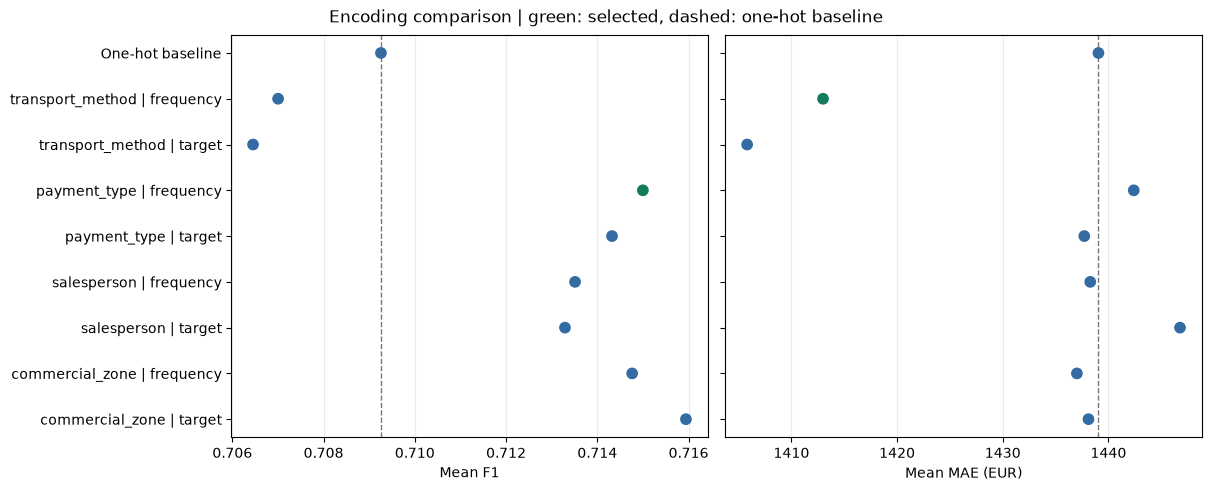

In [5]:
mean_width = scores.groupby("variant", sort=False)["columns"].mean()
by_fold = scores.groupby(["variant", "task", "fold"], sort=False)["score"].mean()
summary = by_fold.groupby(["variant", "task"], sort=False).mean().unstack()
summary = summary.rename(columns={"classification": "Mean F1", "regression": "Mean MAE (EUR)"})
summary.insert(0, "Mean columns", mean_width)
method_order = scores.drop_duplicates("variant").set_index("variant")["method"].map(
    {"one-hot": 0, "frequency": 1, "target": 2}
)

choices = {}
for metric, greater_is_better in (("Mean F1", True), ("Mean MAE (EUR)", False)):
    values = summary[metric]
    eligible = values.ge(values.max() - 0.005) if greater_is_better else values.le(values.min() * 1.01)
    ranking = summary.loc[eligible, ["Mean columns", metric]].assign(priority=method_order)
    choices[metric] = ranking.sort_values(
        ["Mean columns", "priority", metric], ascending=[True, True, not greater_is_better]
    ).index[0]

display(summary.round({"Mean columns": 1, "Mean F1": 4, "Mean MAE (EUR)": 2}))
fold_table = by_fold.unstack(["task", "fold"]).reindex(summary.index)
fold_table = fold_table.rename(columns={"classification": "F1", "regression": "MAE (EUR)"}, level=0)
width_by_fold = scores.groupby(["variant", "fold"])["columns"].first().unstack()
fold_table = pd.concat([fold_table, pd.concat({"Columns": width_by_fold}, axis=1)], axis=1)
display(fold_table.round({column: 4 if column[0] == "F1" else 2 for column in fold_table}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout="constrained")
for ax, metric in zip(axes, choices):
    colors = ["#137b5b" if name == choices[metric] else "#336ba2" for name in summary.index]
    ax.scatter(summary[metric], list(summary.index), color=colors, s=55, zorder=3)
    ax.axvline(summary.loc["One-hot baseline", metric], color="#777777", linestyle="--", linewidth=1)
    ax.set_xlabel(metric)
    ax.grid(axis="x", alpha=0.25)
axes[0].invert_yaxis()
fig.suptitle("Encoding comparison | green: selected, dashed: one-hot baseline")
plt.show()

## Recommendation

In [6]:
for task, metric, decimals in (("Repeat purchase", "Mean F1", 4), ("Conditional spending", "Mean MAE (EUR)", 2)):
    pick = choices[metric]
    row = summary.loc[pick]
    baseline = summary.loc["One-hot baseline"]
    print(
        f"{task}: {pick}. {metric} {row[metric]:.{decimals}f} "
        f"(baseline {baseline[metric]:.{decimals}f}); "
        f"{row['Mean columns']:.1f} mean columns (baseline {baseline['Mean columns']:.1f})."
    )
print("Recommendations are based on development folds. The operational encoder remains one-hot.")

Repeat purchase: payment_type | frequency. Mean F1 0.7150 (baseline 0.7093); 79.5 mean columns (baseline 84.0).
Conditional spending: transport_method | frequency. Mean MAE (EUR) 1412.99 (baseline 1439.05); 65.0 mean columns (baseline 84.0).
Recommendations are based on development folds. The operational encoder remains one-hot.
